# 06 — Study results, uncertainty, and implementation audit

Run after notebook 05 completes. This notebook reads saved results, checks completion and decision support, distinguishes feasible comparisons from unconstrained policy differences, and writes the final Markdown report. It does not tune or fit another model.

All figures and tables describe the specified simulated environments and 200-vehicle portfolios. The public calibration data contain bargaining, while binding floors define an explicit alternative trading institution. No results imply gains in real auctions.


In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t as student_t
from IPython.display import display
OUT=Path('data/study')
results=pd.read_csv(OUT/'all_policy_results.csv')
summary=pd.read_csv(OUT/'policy_summary.csv')
boot=pd.read_csv(OUT/'bootstrap_results.csv')
metadata=json.loads((OUT/'study_metadata.json').read_text())
main=['binding_historical','binding_randomized','bargaining_historical','bargaining_randomized']
assert all(results.loc[results.scenario.eq(s),'replication'].nunique()==30 for s in main)
assert all(results.loc[results.scenario.eq('sensitivity_'+s),'replication'].nunique()==30 for s in metadata['sensitivities'])
assert boot.bootstrap.nunique()==500
assert not results.loc[results.available.eq(True),'expected_value'].isna().any()
solver_counts=results.groupby(['scenario','policy','solver_status'],dropna=False).size().rename('count').reset_index()
solver_counts.to_csv(OUT/'solver_status_counts.csv',index=False)
# Numeric integration can make feasibility ambiguous close to a target.
numerics=pd.read_csv(OUT/'oracle_numerical_checks.csv')
max_q_error=float(numerics.max_q_error.max());max_value_error=float(numerics.max_gross_error.max())
results['near_numerical_conversion_boundary']=(results.expected_conversion-results.target).abs().le(max_q_error)
results.to_csv(OUT/'policy_results_with_numerical_flags.csv',index=False)
# A common candidate set implies a nonincreasing oracle value frontier, allowing the solver gap.
frontier_issues=[]
for (scenario,rep),g in results[results.policy.eq('oracle')&results.available.eq(True)].groupby(['scenario','replication']):
    if (g.sort_values('target').expected_value.diff().dropna()>.05).any():frontier_issues.append((scenario,int(rep)))
assert not frontier_issues, frontier_issues
print('Verified: 30 replications per main/sensitivity scenario; 500 bootstraps; oracle frontiers consistent.')


Verified: 30 replications per main/sensitivity scenario; 500 bootstraps; oracle frontiers consistent.


## Independent oracle and support verification

Check the reference candidate bounds and compare integrated values against fresh Monte Carlo draws from the exact empirical-residual posterior at interior reference floors. These draws are used only to validate the numerical calculation.


In [2]:
# Independent Monte Carlo check of the reference oracle at fixed candidate interventions.
import cloudpickle
from scipy.special import expit
from scipy.stats import norm
study=json.loads(Path('05_single_run_policy_study.ipynb').read_text())
env={'__name__':'study_verification'}
for index in [1,2,4,5,7,9]:
    exec(''.join(study['cells'][index]['source']),env)
with (OUT/'reference_state.pkl').open('rb') as f:reference_model,tr,va,te=cloudpickle.load(f)
portfolio=te.sample(200,random_state=46940).reset_index(drop=True)
maps=env['support_fit'](tr)
grid,_=env['candidates'](portfolio,maps,1.0,0.0)
lo,hi,_=env['bounds_for'](portfolio,maps)
assert ((grid>=lo[:,None]-1e-10)&(grid<=hi[:,None]+1e-10)).all()
original=portfolio.head(6)
small_grid=grid[:6][:,[0,5,10]]
q_integrated,g_integrated=env['oracle'](original,small_grid,'historical','binding')
rng=np.random.default_rng(91740);mc_rows=[]
for i,(_,vehicle) in enumerate(original.iterrows()):
    f=env['fits'][vehicle.seller_group];cfg=env['CONFIG'];meta=env['metadata']
    one=original.iloc[[i]].copy()
    mu=float(f['floor'][0].predict(env['model_frame'](one))[0])
    low,high=f['floor_ratio_bounds']
    if not low<vehicle.floor_ratio<high:
        continue  # Boundary cases are covered by resolution diagnostics, not this interior check.
    residual=f['floor'][1]
    latent_values=(np.log(float(vehicle.floor_ratio))-mu-residual)/cfg['private_floor_strength']
    logweights=-.5*latent_values**2;weights=np.exp(logweights-logweights.max());weights/=weights.sum()
    u=rng.choice(latent_values,size=100000,p=weights)
    shock=rng.normal(0,cfg['market_sd'],len(u))
    for j,a in enumerate(small_grid[i]):
        z=env['model_frame'](one.assign(floor_ratio=a))
        conv=f['conversion'];slope=conv.steps[-1][1].coef_[0,3]/conv.steps[0][1].named_transformers_['num'].scale_[-1]
        base=float(conv.decision_function(z)[0])-slope*a+cfg['floor_effect']*a+meta['conversion_intercept_adjustments'][vehicle.seller_group]
        q=expit(base+cfg['private_sale_strength']*u+shock)
        reg,resid=f['binding'];ordered=np.sort(resid);delta=np.diff(ordered)
        smear=(np.exp(ordered[:-1])*np.divide(np.expm1(delta),delta,out=np.ones_like(delta),where=delta!=0)).mean()
        premium=np.exp(float(reg.predict(z)[0]))*meta['price_calibration'][vehicle.seller_group+'_binding']['multiplier']*smear
        price=float(vehicle.benchmark)*(a+premium*np.exp(cfg['private_price_strength']*u))
        gross=q*price
        qse=q.std(ddof=1)/np.sqrt(len(q));gse=gross.std(ddof=1)/np.sqrt(len(gross))
        mc_rows.append(dict(vehicle=i,floor_ratio=a,q_oracle=q_integrated[i,j],q_mc=q.mean(),q_mcse=qse,
                gross_oracle=g_integrated[i,j],gross_mc=gross.mean(),gross_mcse=gse))
        assert abs(q_integrated[i,j]-q.mean()) < 5*qse+max_q_error
        assert abs(g_integrated[i,j]-gross.mean()) < 5*gse+max_value_error
mc=pd.DataFrame(mc_rows);mc.to_csv(OUT/'oracle_monte_carlo_check.csv',index=False)
assert len(mc)>=9
print('Oracle agrees with independently sampled posterior outcomes within Monte Carlo and integration tolerance.')

# Assess candidate interventions, not just historical-assignment calibration.
expanded=portfolio.loc[portfolio.index.repeat(grid.shape[1])].copy()
expanded['floor_ratio']=grid.ravel()
qh,ph=env['predict'](reference_model,expanded)
qt,gt=env['oracle'](portfolio,grid,'historical','binding')
response=expanded[['vehicle_id','seller_group','floor_ratio']].copy().reset_index(drop=True)
response['predicted_conversion']=qh;response['oracle_conversion']=qt.ravel()
response['predicted_price']=ph;response['oracle_conditional_price']=(gt/qt).ravel()
response=response.drop_duplicates(['vehicle_id','floor_ratio'])
response['floor_band']=pd.cut(response.floor_ratio,[0,.75,1,1.25,1.5,2,np.inf]).astype(str)
response.to_csv(OUT/'candidate_response_diagnostics.csv',index=False)
response_groups=response.groupby(['seller_group','floor_band']).agg(
    candidate_points=('vehicle_id','size'),predicted_conversion=('predicted_conversion','mean'),
    oracle_conversion=('oracle_conversion','mean'),predicted_price=('predicted_price','mean'),
    oracle_conditional_price=('oracle_conditional_price','mean')).reset_index()
response_groups.to_csv(OUT/'candidate_response_group_summary.csv',index=False)
order=np.argsort(grid,axis=1)
qt_sorted=np.take_along_axis(qt,order,axis=1)
qh_sorted=np.take_along_axis(qh.reshape(grid.shape),order,axis=1)
assert (np.diff(qt_sorted,axis=1)<=1e-8).all()
monotonicity=dict(vehicles=len(portfolio),predicted_increase_fraction=float((np.diff(qh_sorted,axis=1)>1e-6).any(axis=1).mean()),
                  oracle_increase_fraction=0.0)
(OUT/'candidate_monotonicity.json').write_text(json.dumps(monotonicity,indent=2))
print('Candidate response diagnostics and support checks saved.')


Oracle agrees with independently sampled posterior outcomes within Monte Carlo and integration tolerance.


Candidate response diagnostics and support checks saved.


## Feasible policy comparisons and sensitivity contrasts

A positive value difference alone does not establish dominance if conversion requirements differ. The following table restricts each paired comparison to replications where both policies satisfy the integrated expected-conversion constraint. The ordinary all-pair table remains available separately; both sample counts are reported. Feasibility uses the numerical oracle and is flagged near its integration resolution.

Sensitivity contrasts pair equal seeds with the main binding/historical environment. Because scenarios differ intentionally, these are within-simulation changes, not causal estimates for observed auctions.


In [3]:
def summarize_delta(delta):
    delta=delta.dropna();n=len(delta)
    mean=delta.mean() if n else np.nan;se=delta.std(ddof=1)/np.sqrt(n) if n>1 else np.nan
    margin=student_t.ppf(.975,n-1)*se if n>1 else np.nan
    return dict(n=n,mean=mean,mcse=se,lower=mean-margin,upper=mean+margin)
feasible_rows=[]
for (scenario,target),g in results.groupby(['scenario','target']):
    opt=g[g.policy.eq('optimized')].set_index('replication')
    for baseline in ['assigned_supported','common','proportional_reduction']:
        other=g[g.policy.eq(baseline)].set_index('replication')
        pair=opt[['expected_value','true_feasible','near_numerical_conversion_boundary']].join(
             other[['expected_value','true_feasible','near_numerical_conversion_boundary']],lsuffix='_optimized',rsuffix='_baseline',how='inner')
        ok=pair.true_feasible_optimized.eq(True)&pair.true_feasible_baseline.eq(True)
        safe=ok&~pair.near_numerical_conversion_boundary_optimized&~pair.near_numerical_conversion_boundary_baseline
        for label,use in [('both_feasible',ok),('both_feasible_away_from_numeric_boundary',safe)]:
            delta=pair.loc[use,'expected_value_optimized']-pair.loc[use,'expected_value_baseline']
            feasible_rows.append(dict(scenario=scenario,target=target,baseline=baseline,comparison=label,**summarize_delta(delta)))
feasible=pd.DataFrame(feasible_rows);feasible.to_csv(OUT/'feasible_paired_value_differences.csv',index=False)
sensitivity=[]
base=results[results.scenario.eq('binding_historical')&results.policy.eq('optimized')&results.target.eq(.6)].set_index('replication')
for name in metadata['sensitivities']:
    g=results[results.scenario.eq('sensitivity_'+name)&results.policy.eq('optimized')].set_index('replication')
    for metric in ['expected_value','expected_conversion']:
        sensitivity.append(dict(scenario=name,metric=metric,**summarize_delta(g[metric]-base[metric])))
sensitivity=pd.DataFrame(sensitivity);sensitivity.to_csv(OUT/'paired_sensitivity_effects.csv',index=False)
display(summary[summary.target.eq(.6)&summary.scenario.isin(main)])


,scenario,target,policy,replications,availability,expected_conversion,expected_value,expected_gross,true_feasible_rate,realized_shortfall_rate,regret
10,bargaining_historical,0.6,assigned_supported,30,1.0,0.512185,7950.079233,4864.768859,0.000000,0.966667,NaN
11,bargaining_historical,0.6,common,30,1.0,0.652878,8014.617100,5535.586107,1.000000,0.033333,322.475674
12,bargaining_historical,0.6,optimized,30,1.0,0.660359,8196.517491,5339.695673,1.000000,0.033333,140.575282
13,bargaining_historical,0.6,oracle,30,1.0,0.600002,8337.092774,5231.857838,1.000000,0.433333,0.000000
14,bargaining_historical,0.6,proportional_reduction,30,1.0,0.622927,7736.861559,5411.340045,0.833333,0.266667,620.460592
35,bargaining_randomized,0.6,assigned_supported,30,1.0,0.536956,7895.099163,4724.753853,0.000000,0.933333,NaN
36,bargaining_randomized,0.6,common,30,1.0,0.652608,8011.861815,5528.460453,1.000000,0.033333,326.080485
37,bargaining_randomized,0.6,optimized,30,1.0,0.653866,8191.176542,5327.126025,1.000000,0.000000,146.765758
38,bargaining_randomized,0.6,oracle,30,1.0,0.600002,8337.942300,5205.924389,1.000000,0.433333,0.000000
39,bargaining_randomized,0.6,proportional_reduction,30,1.0,0.624196,7727.578057,5167.195465,0.833333,0.166667,628.151386


## Prediction diagnostics by floor range and seller group

Aggregate held-out prediction-group statistics across independent replications, weighting conversion by group sample count. These historical-assignment checks do not establish causal calibration at alternative floors; the intervention-policy evaluation supplies that separate comparison.


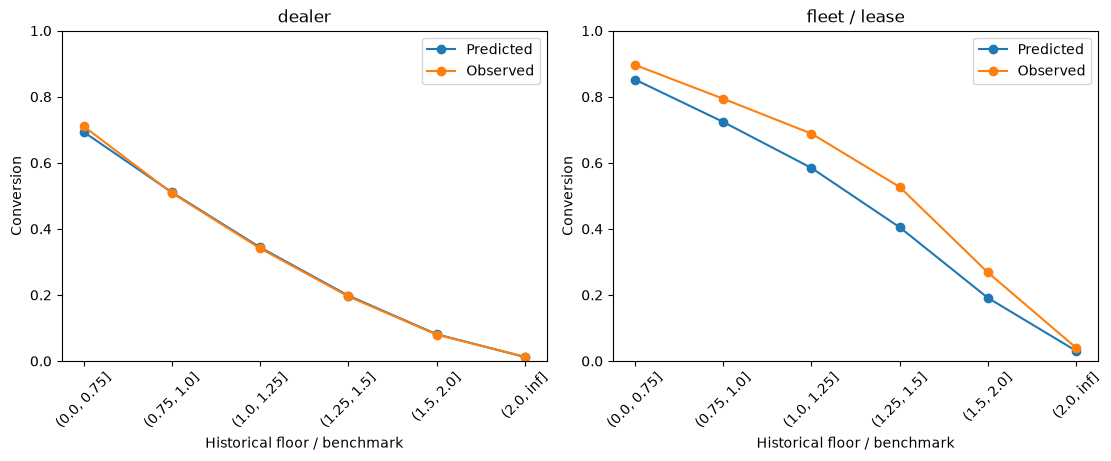

In [4]:
tables=[]
for scenario in main:
    for file in sorted((OUT/scenario).glob('prediction_groups_*.csv')):
        d=pd.read_csv(file);d['scenario']=scenario;tables.append(d)
groups=pd.concat(tables,ignore_index=True)
groups['predicted_sales']=groups.predicted*groups.n;groups['observed_sales']=groups.observed*groups.n
pooled=groups.groupby(['scenario','seller_group','floor_band']).agg(n=('n','sum'),predicted_sales=('predicted_sales','sum'),observed_sales=('observed_sales','sum')).reset_index()
pooled['predicted']=pooled.predicted_sales/pooled.n;pooled['observed']=pooled.observed_sales/pooled.n
pooled.to_csv(OUT/'pooled_floor_range_calibration.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
for ax,group in zip(axes,['dealer','fleet_lease']):
    d=pooled[pooled.scenario.eq('binding_historical')&pooled.seller_group.eq(group)].copy()
    order=['(0.0, 0.75]','(0.75, 1.0]','(1.0, 1.25]','(1.25, 1.5]','(1.5, 2.0]','(2.0, inf]']
    d['order']=d.floor_band.map({k:i for i,k in enumerate(order)});d=d.sort_values('order')
    ax.plot(d.floor_band,d.predicted,'o-',label='Predicted');ax.plot(d.floor_band,d.observed,'o-',label='Observed')
    ax.set(title=group.replace('_',' / '),xlabel='Historical floor / benchmark',ylabel='Conversion',ylim=(0,1))
    ax.tick_params(axis='x',labelrotation=45);ax.legend()
fig.savefig(OUT/'floor_range_prediction_diagnostics.png',dpi=180);plt.show()


In [5]:
def table_markdown(d):
    cols=list(d.columns)
    lines=['| '+' | '.join(cols)+' |','| '+' | '.join(['---']*len(cols))+' |']
    for row in d.itertuples(index=False,name=None):
        lines.append('| '+' | '.join('—' if pd.isna(x) else f'{x:.3f}' if isinstance(x,(float,np.floating)) else str(x) for x in row)+' |')
    return '\n'.join(lines)
primary=summary[summary.scenario.eq('binding_historical')&summary.target.eq(.6)][['policy','replications','availability','expected_conversion','expected_value','true_feasible_rate','realized_shortfall_rate','regret']]
boot_intervals=pd.read_csv(OUT/'bootstrap_intervals.csv')
bi=boot_intervals[boot_intervals.policy.eq('optimized')]
frontier=summary[summary.scenario.isin(['binding_historical','binding_randomized','bargaining_historical','bargaining_randomized'])].copy()
frontier['feasible_delivery_rate']=frontier.availability*frontier.true_feasible_rate
frontier.to_csv(OUT/'capstone_all_targets.csv',index=False)
frontier_display=frontier[frontier.policy.eq('optimized')][['scenario','target','availability','expected_conversion','expected_value','feasible_delivery_rate']]
text=f"""# Single-run capstone study: simulation results

## Scope and completed computations

The Introduction and Methods governs this implementation. Sources are Larsen's public replication assets; no employer data were used. The source archive remains unchanged. Four main scenarios each received 30 independently generated 50,000-vehicle datasets with predictive-model refits (120 main runs). Nine single-factor sensitivity scenarios each received 30 paired runs (270 sensitivity runs). A further 500 date-block bootstrap samples refitted the models and recomputed recommendations. Policy portfolios contain 200 randomly selected test vehicles per replication; the complete approximately 10,000-vehicle test split supplies predictive diagnostics.

Main scenarios cross binding versus bargaining prices and historical versus randomized floor assignment. Train/validation/test splits preserve dates. Fixed predictive specifications follow the development comparisons; model coefficients, preprocessing, smearing, support bounds, and validation calibration are refitted. The primary analysis uses chronological validation only. The independently labeled target-period correction in notebook 04 is a supplementary experiment and is not passed off as a forecast without target-period labels.

## Main results across conversion targets

The main analysis evaluates required expected-conversion targets of 40%, 50%, 60%, 70%, and 80%. These are study scenarios, not empirically established business requirements. No single target is recommended. The capstone presents how expected seller value, achieved expected conversion, and policy availability change across the full target grid.

![Conversion–value tradeoff and policy feasibility](conversion_value_frontier.png)

The optimized-policy results for all four environments are below. The complete five-policy comparison is saved in `capstone_all_targets.csv`.

{table_markdown(frontier_display)}

Expected conversion and value are conditional on an available solution. `feasible_delivery_rate` counts unavailable solutions as failures and reports the fraction of all replications delivering a policy that meets the integrated expected-conversion target. Conditional means at high targets must be read with availability; they do not describe success in every replication. The oracle provides the constrained benchmark, while fitted policies may overshoot or miss the target.

## Illustrative policy comparison at 60% required conversion

The 60% target is an illustrative intermediate case, not the headline objective or an estimated optimal business target. The supported assigned-floor baseline achieves approximately 51% expected conversion in this environment, so this example illustrates a requirement above that baseline.

{table_markdown(primary)}

Value is expected seller value per offered vehicle, including the unsold asset. True feasibility refers to integrated generator probabilities, not an empirical auction guarantee. `assigned_supported` retains recorded floors where supported and clips them otherwise; it is explicitly not an exact unmodified-recorded-floor baseline. Baseline parameters are selected on validation data. Availability below one indicates infeasibility or a solver termination without a proven accepted solution; see solver_status_counts.csv.

At the 80% target, the fitted optimizer returns a solution in only 8 of 30 primary replications. The frontier figure marks that conditional mean separately; its feasibility panel counts unavailable solutions as failures to deliver a feasible policy.

## Policy comparisons and uncertainty

`paired_policy_differences.csv` contains paired means, Monte Carlo standard errors, and 95% Student-t intervals for all available policy pairs. `feasible_paired_value_differences.csv` additionally restricts comparisons to mutually feasible policies and separately excludes numerically borderline cases. An apparent value advantage over a policy with a different feasibility status is not evidence of feasible dominance. Regret is calculated only for feasible fitted policies with an available oracle; its average is conditional on those cases.

The optimized policy's conditional bootstrap intervals for the illustrative 60% target are shown below. Bootstrap refits and the nine sensitivity experiments were conducted at this target only; their uncertainty and robustness findings must not be generalized to the full target grid. The main replicated study supplies target-specific comparisons across all five targets.

{table_markdown(bi[['metric','n','median','lower','upper']])}

Bootstrap date blocks preserve common market shocks; training and validation are resampled separately and the test portfolio is fixed. These percentile intervals characterize estimation variability conditional on the reference environment and portfolio. They do not measure simulator misspecification or real-market uncertainty.

## Oracle information and numerical limits

The oracle shares observable information, including the fixed recorded floor being reconsidered. In historical scenarios, that recorded floor informs the private-signal posterior. Candidate floors never replace the reference floor in that posterior. Private signal and unknown date shock are integrated out; expected gross proceeds use the joint expectation of sale probability times conditional price. Stored realized private signals are never supplied to prediction or oracle optimization.

The largest 41-versus-81-node private-integration difference on sampled vehicles was {max_q_error:.6f} in probability and ${max_value_error:.3f} in expected gross proceeds. These checks are estimates of numerical sensitivity, not rigorous error bounds. Near-boundary feasibility is flagged using the largest checked probability difference, and small regret differences should not be interpreted more precisely than this integration and solver resolution. Oracle frontiers were checked for monotonicity within solver tolerance.

## Sensitivities and remaining limitations

`paired_sensitivity_effects.csv` pairs seeds to assess holding costs ($100/$600), retained value (75%/95% of benchmark), smaller training samples (10,000 total vehicles), absent/stronger private information, and weaker/stronger demand. Source parameters are not recalibrated to erase sensitivity changes. Conversion-value and feasibility figures are saved alongside the tables.

These conclusions apply to the calibrated simulation. The full source-versus-synthetic price distributions still differ, especially because binding floors cannot reproduce Larsen's below-reserve bargaining trades. Make is used as the available vehicle category; it is not a validated segment mapping. Source run proportions define the synthetic seller-group mixture and do not identify a unique-vehicle population mix. Costs, private-information effects, the causal floor slope, and the high-bid mechanism remain explicit assumptions. Candidate support reduces extrapolation but does not remove confounding. Probability calibration on historical floors does not guarantee calibrated intervention predictions.

No live-auction benefit or economic-welfare improvement is established. Repeated auctions remain the separately deferred extension. Future empirical evaluation is outside this single-run simulation study.

## Reproducibility

Run notebooks 01–06 in order. Notebook 05 checkpoints replications and bootstrap fits; delete or relocate the relevant generated checkpoint directory before intentionally changing a study specification. `study_metadata.json` records study settings and packages; calibration metadata records fixed source fingerprints and generator parameters. Source CSVs and codebook are untouched. Study outputs are under `data/study/`; earlier pilot checkpoints in `data/study_initial_checks/` are superseded and must not be mixed with final results.
"""
(OUT/'study_report.md').write_text(text)
# Completion manifest is separate from claims about external validity.
completion=pd.DataFrame([
 ('Floor-range prediction diagnostics','complete','pooled_floor_range_calibration.csv'),
 ('Training-supported candidate floors','complete','reference_decisions.csv'),
 ('Optimization and three baseline policies','complete','all_policy_results.csv'),
 ('Observable-information oracle','complete with numerical approximation','oracle_numerical_checks.csv'),
 ('30 independent refits per main scenario','complete','policy_summary.csv'),
 ('Nine sensitivity scenarios, 30 paired runs each','complete','paired_sensitivity_effects.csv'),
 ('500 date-block bootstrap refits','complete','bootstrap_intervals.csv'),
 ('Paired uncertainty and feasibility-aware comparisons','complete','feasible_paired_value_differences.csv'),
 ('Report and figures','complete','study_report.md'),
 ('Repeated-auction extension','deferred by Methods','not part of primary single-run study'),
],columns=['requirement','status','artifact'])
completion.to_csv(OUT/'completion_manifest.csv',index=False)
display(completion)
print('Report:',(OUT/'study_report.md').resolve())


,requirement,status,artifact
0,Floor-range prediction diagnostics,complete,pooled_floor_range_calibration.csv
1,Training-supported candidate floors,complete,reference_decisions.csv
2,Optimization and three baseline policies,complete,all_policy_results.csv
3,Observable-information oracle,complete with numerical approximation,oracle_numerical_checks.csv
4,30 independent refits per main scenario,complete,policy_summary.csv
5,"Nine sensitivity scenarios, 30 paired runs each",complete,paired_sensitivity_effects.csv
6,500 date-block bootstrap refits,complete,bootstrap_intervals.csv
7,Paired uncertainty and feasibility-aware compa...,complete,feasible_paired_value_differences.csv
8,Report and figures,complete,study_report.md
9,Repeated-auction extension,deferred by Methods,not part of primary single-run study


Report: /Users/ecilteodoro/Library/Mobile Documents/com~apple~CloudDocs/UWF/2026-8/IDC6940/code-repo/data/study/study_report.md
